# Gain coordinates, objective, and feasibility

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Eight gains in logarithmic coordinates

Each optimizer works with u in [0,1]. Physical gain is `exp(log(lower)+u*log(upper/lower))`. The controller structure stays fixed: six roll/pitch outer/inner parameters and two yaw PI gains.


In [2]:
cfg=load_json(study('GA')/'config.json')
show_table(cfg['parameters'])
show_source(study('GA')/'study.py','decode')
show_source(study('GA')/'study.py','encode')


name,lower,upper,scale
roll_outer_K,1.0,30.0,log
roll_inner_Kp_equivalent,0.005,0.35,log
roll_inner_Ki_equivalent,0.0001,1.5,log
pitch_outer_K,1.0,30.0,log
pitch_inner_Kp_equivalent,0.005,0.35,log
pitch_inner_Ki_equivalent,0.0001,1.5,log
yaw_Kp,0.01,1.0,log
yaw_Ki,0.0001,0.5,log


def decode(unit,cfg):
    values=np.empty_like(unit)
    for j,p in enumerate(cfg['parameters']):
        if p['scale']=='log': values[...,j]=np.exp(np.log(p['lower'])+unit[...,j]*np.log(p['upper']/p['lower']))
        else: values[...,j]=p['lower']+unit[...,j]*(p['upper']-p['lower'])
    return values

def encode(gains,cfg):
    vals=np.empty_like(gains)
    for j,p in enumerate(cfg['parameters']):
        vals[j]=(np.log(gains[j]/p['lower'])/np.log(p['upper']/p['lower']) if p['scale']=='log'
                 else (gains[j]-p['lower'])/(p['upper']-p['lower']))
    return np.clip(vals,0,1)

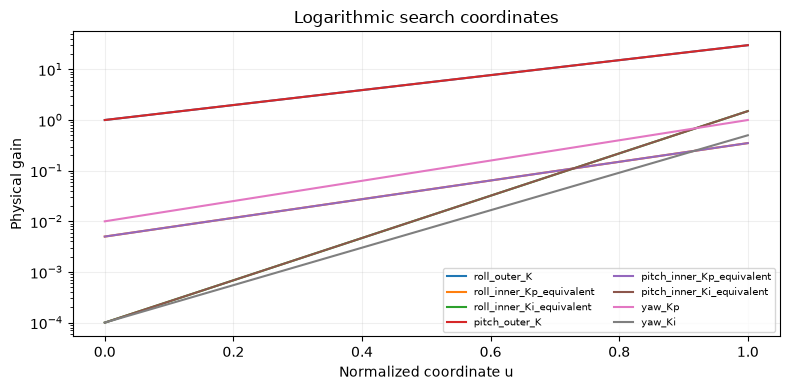

In [3]:
fig,ax=plt.subplots(figsize=(8,4)); u=np.linspace(0,1,101)
for p in cfg['parameters']:
    gain=np.exp(np.log(p['lower'])+u*np.log(p['upper']/p['lower']))
    ax.plot(u,gain,label=p['name'])
ax.set(xlabel='Normalized coordinate u',ylabel='Physical gain',yscale='log',title='Logarithmic search coordinates')
ax.legend(fontsize=7,ncol=2); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)


## Quality and constraints

The per-channel score weights settling (0.45), rise (0.20), ITAE (0.25), and IAE (0.10), normalized by horizon and command. Across scenarios, quality Q uses 70% mean speed and 30% worst speed plus effort weight 0.01. Infeasible candidates receive `1000+100*V+(2/pi)*atan(Q)`. Lower is better within the same regime; penalized fitness is not a time or a percentage improvement.


In [4]:
show_source(study('GA')/'study.py','assess')
show_source(study('GA')/'study.py','evaluate')


def assess(metrics,diag,scenario,cfg):
    active=np.abs(scenario['target'])>1e-12
    horizon=scenario.get('horizon',cfg['response_horizon_s'])
    w=cfg['fitness_weights']
    # Dimensionless weighted mean over commanded channels.
    channel=(w['settling']*metrics[:,1]/horizon + w['rise']*metrics[:,0]/horizon
             +w['itae']*2*metrics[:,5]/horizon**2+w['iae']*metrics[:,4]/horizon)
    speed=float(np.mean(channel[active]))
    # Feasibility is independent of weights; infeasible members cannot beat feasible ones.
    violation=0.
    violation+=float(np.sum(np.maximum(0.,metrics[active,2]/cfg['max_overshoot_fraction']-1)))
    violation+=float(np.sum(np.maximum(0.,metrics[active,3]/cfg['max_final_error_fraction']-1)))
    violation+=float(np.sum(1-metrics[active,8]))
    violation+=max(0.,diag[0]/cfg['max_motor_clipping_fraction']-1)
    # Uncommanded roll/pitch must stay below 0.5 deg; uncommanded yaw below 3 deg/s.
    crosslimit=np.deg2rad([.5,.5,3.])
    violation+=float(np.sum(np.maximum(0.,metrics[~active,6]/crosslimit[~active]-1)))
    violation+=max(0.,diag[4]/np.deg2rad(75)-1)
    # Keep the source equations; constrain optimization to nonnegative motor speeds.
    violation+=max(0.,(cfg.get('minimum_motor_speed_rad_s',0.)-diag[6])/100.)
    if diag[5]: violation+=1000.
    if not np.isfinite(metrics).all() or not np.isfinite(diag).all():
        return {'speed':1e3,'violation':1e6,'effort':1.,'feasible':False}
    return {'speed':speed,'violation':float(violation),'effort':float(diag[3]),'feasible':bool(violation<=1e-10)}

def evaluate(gains,scenarios,cfg,details=False):
    cases=[]; assessments=[]
    for scenario in scenarios:
        m,d,_=run(gains,scenario,cfg)
        a=assess(m,d,scenario,cfg)
        assessments.append(a)
        if details: cases.append({'scenario':scenario,'metrics':m.tolist(),'diagnostics':d.tolist(),**a})
    speeds=np.array([a['speed'] for a in assessments]); worst=cfg['worst_case_weight']
    quality=(1-worst)*speeds.mean()+worst*speeds.max()+cfg['effort_weight']*np.mean([a['effort'] for a in assessments])
    violation=sum(a['violation'] for a in assessments)
    # atan bounds the tie-breaking quality term below 1, guaranteeing feasibility priority.
    value=float(quality if violation<=1e-10 else 1000.+100.*violation+2/np.pi*np.arctan(quality))
    return (value,cases) if details else value

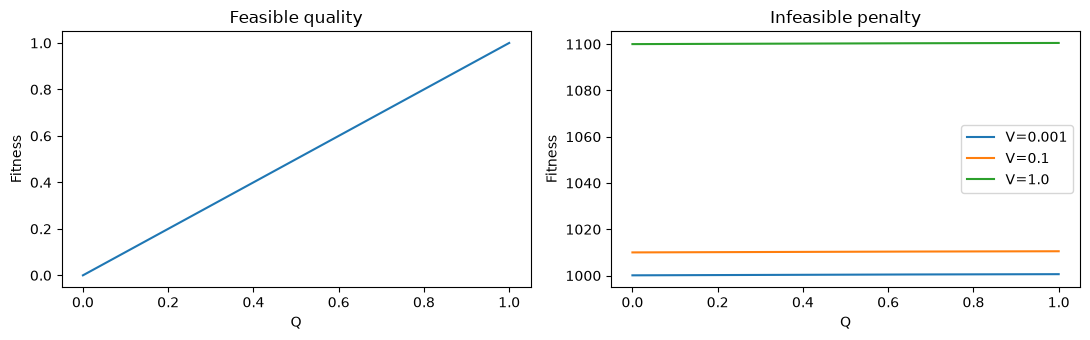

In [5]:
quality=np.linspace(0,1,200)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(quality,quality); axes[0].set(title='Feasible quality',xlabel='Q',ylabel='Fitness')
for violation in [0.001,0.1,1.0]:
    axes[1].plot(quality,1000+100*violation+2/np.pi*np.arctan(quality),label=f'V={violation}')
axes[1].set(title='Infeasible penalty',xlabel='Q',ylabel='Fitness'); axes[1].legend()
fig.tight_layout(); plt.show(); plt.close(fig)


## Training and hold-outs
Nominal training uses six single-axis commands. Later robust training adds 24 uncertain-plant cases. Do not substitute the smaller original three-seed robustness protocol for the later 30-seed protocol.


In [6]:
show_source(study('GA')/'study.py','training_scenarios')
show_source(study('ALNS')/'robust_protocol.py','training_cases')
show_source(study('ALNS')/'robust_protocol.py','validation_cases')


def training_scenarios():
    return [{'name':name, 'target':target, 'group':'training'} for name,target in [
        ('roll_5deg',[5,0,0]),('roll_20deg',[20,0,0]),
        ('pitch_5deg',[0,5,0]),('pitch_20deg',[0,20,0]),
        ('yaw_30dps',[0,0,30]),('yaw_100dps',[0,0,100])]]

def training_cases():
    cases=training_scenarios()
    # Six independent Latin-hypercube plants plus two directed boundary plants.
    units=qmc.LatinHypercube(d=9,seed=TRAIN_SEED).random(6).tolist()
    units += [[1,1,1,1,0,0,0,0,0],[0,0,0,0,1,1,1,1,1]]
    for i,u in enumerate(units):
        for axis,amp in enumerate([20,20,100]):
            target=[0,0,0]; target[axis]=amp
            cases.append({'name':f'train_plant{i}_axis{axis}','target':target,
                          'plant':plant_from_unit(u).tolist(),'group':'uncertain_training'})
    return cases

def validation_cases():
    rng=np.random.default_rng(TEST_SEED); cases=[]
    # Uniform independent draws, with 100 unseen commands for each single axis.
    for i in range(300):
        j=i%3; target=[0.,0.,0.]
        target[j]=float(rng.choice([-1,1])*rng.uniform(5 if j<2 else 20,20 if j<2 else 100))
        cases.append({'name':f'mc_{i:03d}','target':target,'plant':plant_from_unit(rng.random(9)).tolist(),
                      'group':'single_axis_mc'})
    # Independent one-at-a-time limits isolate the sensitivity to each coefficient.
    for factor,(_,_,_) in enumerate(FACTORS):
        for edge in [0.,1.]:
            u=np.full(9,.5); u[factor]=edge
            for j,amp in enumerate([20,20,100]):
                target=[0,0,0]; target[j]=amp
                cases.append({'name':f'oat_{FACTORS[factor][0]}_{int(edge)}_{j}',
                              'target':target,'plant':plant_from_unit(u).tolist(),'group':'one_at_a_time'})
    # Separate structural stress test: NOT mixed with the primary robustness score.
    for i in range(90):
        target=(rng.choice([-1,1],3)*rng.uniform([5,5,20],[18,15,70])).tolist()
        cases.append({'name':f'combined_{i:03d}','target':target,'plant':plant_from_unit(rng.random(9)).tolist(),
                      'throttle':float(rng.uniform(.54,.68)),'group':'combined_stress'})
    return cases